# 04 · Structural similarity of the active site (SOAP) vs sequence measures
**Question.** Do local structure descriptors around the nucleophile agree with sequence-based neighbours?
**Inputs.** `data/derived/soap.npz`: SOAP (r_cut 8 Å, n_max = l_max = 8) centred on the nucleophile atom of each elbow, from the AlphaFold models.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path; sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> ../src
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from abhd import config as C, data as D, plots as P
pd.set_option("display.width", 160, "display.max_colwidth", 60)
meta = D.load_entries()

In [2]:
soap = pd.read_csv(C.SOAP_COS, index_col=0); pb = pd.read_csv(C.PROTBERT_COS, index_col=0)
v = soap.values[np.triu_indices(len(soap), 1)]
print(f"{len(soap)} structures; SOAP cosine distance quantiles (0,1%,10%,50%,90%,100%):", np.quantile(v, [0, .01, .1, .5, .9, 1]).round(4))

160 structures; SOAP cosine distance quantiles (0,1%,10%,50%,90%,100%): [0.     0.0004 0.0039 0.0164 0.0687 0.2105]


## Neighbours of ABHD2 and ABHD14B under each measure

In [3]:
ff, ev = D.load_funfam()
def ff_nb(gene, n=5):
    fid = ff.index[ff.human_genes.str.split(";").apply(lambda g: gene in g)][0]
    s = ev[fid].drop(fid).sort_values().head(n)
    return [f"{ff.loc[i,'human_genes'].split(';')[0]} ({e:.0e})" for i, e in s.items()]
out = {}
for g in ["ABHD2", "ABHD14B"]:
    a = D.reviewed_accession(meta, g)
    out[g] = pd.DataFrame({
        "FunFam HHalign": ff_nb(g),
        "ProtBert": [f"{r.gene} ({r.distance:.3f})" for r in D.nearest(pb, a, meta, 5).itertuples()],
        "SOAP (nucleophile)": [f"{r.gene} ({r.distance:.4f})" for r in D.nearest(soap, a, meta, 5).itertuples()]})
    print(g); display(out[g])

ABHD2


,FunFam HHalign,ProtBert,SOAP (nucleophile)
0,ABHD3 (1e-32),ABHD3 (0.028),ABHD3 (0.0013)
1,ABHD1 (1e-22),SPG21 (0.048),ABHD14B (0.0019)
2,ABHD15 (2e-11),LPL (0.050),ABHD6 (0.0019)
3,ABHD8 (2e-05),ABHD16A (0.052),ABHD18 (0.0024)
4,LDAH (2e-05),BPHL (0.055),LIPN (0.0031)


ABHD14B


,FunFam HHalign,ProtBert,SOAP (nucleophile)
0,ABHD14A (3e-69),ABHD14A (0.043),ABHD2 (0.0019)
1,EPHX3 (2e-22),ABHD8 (0.048),ABHD14A (0.0025)
2,ABHD11 (7e-19),ABHD11 (0.049),ABHD6 (0.0029)
3,EPHX2 (4e-18),PLA2G15 (0.052),ABHD3 (0.0030)
4,ABHD6 (3e-14),BPHL (0.057),PPME1 (0.0033)


**Reading this.** The three measures agree on the closest paralog and little beyond it. ABHD3 is ABHD2's nearest neighbour under all three; for ABHD14B,
ABHD14A is first under FunFam and ProtBert and second under SOAP (after ABHD2). SOAP neighbours are the most mixed (ABHD14B, ABHD6, ABHD18 and LIPN for ABHD2): the nucleophile environment is highly
conserved across the fold, so SOAP distances are small for everything (median ≈ 0.016) and differences between the top few are small.
Do not read the order within the top-5 as meaningful (not tested for robustness).

## Do ProtBert and SOAP distances agree overall?

Spearman rho between ProtBert and SOAP pairwise distances (160 proteins, 12720 pairs): 0.15


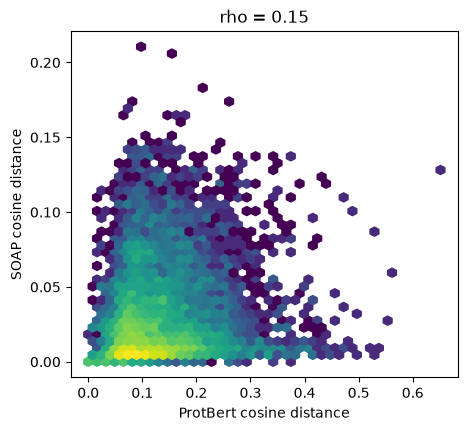

In [4]:
from scipy.stats import spearmanr
common = [a for a in soap.index if a in pb.index]
iu = np.triu_indices(len(common), 1)
a = pb.loc[common, common].values[iu]; b = soap.loc[common, common].values[iu]
rho = spearmanr(a, b).correlation
print(f"Spearman rho between ProtBert and SOAP pairwise distances ({len(common)} proteins, {len(a)} pairs): {rho:.2f}")
fig, ax = plt.subplots(figsize=(5, 4.5)); ax.hexbin(a, b, gridsize=40, mincnt=1, bins="log")
ax.set(xlabel="ProtBert cosine distance", ylabel="SOAP cosine distance", title=f"rho = {rho:.2f}"); plt.show()

**Reading this.** Pairwise distances are only treated as a rough check (pairs are not independent, so the correlation has no p-value
interpretation). A low rho (about 0.15 here) means sequence and nucleophile-environment geometry carry different information, consistent with
functional similarity not tracking the ABHD name.

## SOAP map

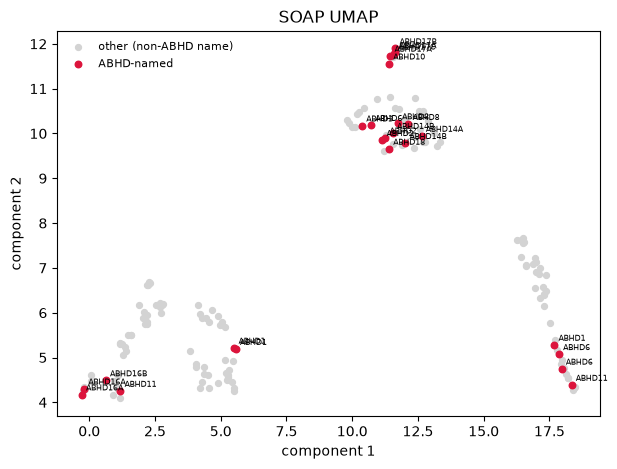

In [5]:
z = np.load(C.SOAP_NPZ); accs = list(z["accessions"]); U = D.umap_coords(z["X"])
m = meta.loc[accs]; is_abhd = m.abhd_named.values
hover = [f"<b>{m.gene_name.iloc[i]}</b><br>{accs[i]}<br>{m.entry_name.iloc[i]}" for i in range(len(accs))]
P.interactive_scatter(U, hover, {"other": (np.where(~is_abhd)[0], "lightgrey"), "ABHD-named": (np.where(is_abhd)[0], "crimson")},
                      "SOAP UMAP (nucleophile environment)", "soap_umap.html")
fig, ax = plt.subplots(figsize=(7, 5)); P.scatter_abhd(U, m.gene_name.values, is_abhd, "SOAP UMAP", ax); plt.show()